In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns


In [2]:
train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')

In [3]:
train.sample(5)

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
972,973,120,RL,55.0,7892,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,99500
595,596,20,RL,69.0,11302,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,8,2006,New,Partial,319000
1214,1215,85,RL,69.0,10205,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2006,WD,Normal,134500
1320,1321,20,RL,70.0,8400,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,6,2009,WD,Normal,156500
1021,1022,20,RL,64.0,7406,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,7,2006,New,Partial,194000


In [4]:
train.shape

(1460, 81)

In [5]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [8]:
train.isnull().sum()[train.isnull().sum()>0]

LotFrontage      259
Alley           1369
MasVnrType       872
MasVnrArea         8
BsmtQual          37
BsmtCond          37
BsmtExposure      38
BsmtFinType1      37
BsmtFinType2      38
Electrical         1
FireplaceQu      690
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
PoolQC          1453
Fence           1179
MiscFeature     1406
dtype: int64

In [9]:
#droped because  too much missing value 
train = train.drop(['Alley' , 'MasVnrType' , 'FireplaceQu' , 'PoolQC' , 'Fence' , 'MiscFeature' ],axis=1)
test = test.drop(['Alley' , 'MasVnrType' , 'FireplaceQu' , 'PoolQC' , 'Fence' , 'MiscFeature' ],axis=1)

In [10]:
pd.set_option('display.max_columns', None) # tells panda to display all columns 

In [19]:
train.sample(5)

,MSSubClass,MSZoning,LotFrontage,LotArea,LotShape,LandContour,LotConfig,LandSlope,Neighborhood,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,Exterior1st,Exterior2nd,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtUnfSF,TotalBsmtSF,HeatingQC,CentralAir,1stFlrSF,2ndFlrSF,GrLivArea,BsmtFullBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,WoodDeckSF,SaleType,SaleCondition,SalePrice
1181,120,RM,64.0,5587,IR1,HLS,Inside,Mod,Crawfor,TwnhsE,1Story,8,5,2008,2008,Hip,CemntBd,CmentBd,186.0,Ex,TA,PConc,Ex,TA,Gd,GLQ,1480,120,1600,Ex,Y,1652,0,1652,1,2,0,2,1,Gd,5,Typ,1,Attchd,2008.0,Fin,2,482,TA,162,New,Partial,392500
622,20,RL,71.0,7064,Reg,Lvl,Inside,Gtl,Sawyer,1Fam,1Story,5,6,1977,1977,Gable,Plywood,Plywood,153.0,TA,TA,CBlock,TA,TA,No,BLQ,560,420,980,TA,Y,980,0,980,0,1,0,3,1,TA,6,Typ,0,Detchd,1986.0,Unf,2,484,TA,192,WD,Normal,135000
240,20,FV,75.0,9000,Reg,Lvl,Inside,Gtl,Somerst,1Fam,1Story,8,5,2008,2008,Gable,VinylSd,VinylSd,36.0,Gd,TA,PConc,Gd,TA,Av,GLQ,1078,488,1566,Ex,Y,1566,0,1566,1,2,0,3,1,Gd,7,Typ,0,Attchd,2008.0,RFn,2,750,TA,144,WD,Normal,262500
538,20,RL,NaN,11553,IR1,Lvl,Inside,Gtl,Sawyer,1Fam,1Story,5,5,1968,1968,Hip,Plywood,Plywood,188.0,TA,TA,CBlock,TA,TA,No,BLQ,673,378,1051,TA,Y,1159,0,1159,0,1,1,3,1,TA,7,Typ,1,Attchd,1968.0,Unf,1,336,TA,466,WD,Normal,158000
930,20,RL,73.0,8925,IR1,HLS,Inside,Gtl,Timber,1Fam,1Story,8,5,2007,2007,Gable,VinylSd,VinylSd,0.0,Gd,TA,PConc,Gd,TA,Av,GLQ,16,1450,1466,Ex,Y,1466,0,1466,0,2,0,3,1,Gd,7,Typ,0,Attchd,2007.0,Fin,3,610,TA,100,WD,Normal,201000


In [11]:
train.corr(numeric_only=True)

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,TotRmsAbvGrd,Fireplaces,GarageYrBlt,GarageCars,GarageArea,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
Id,1.000000,0.011156,-0.010601,-0.033226,-0.028365,0.012609,-0.012713,-0.021998,-0.050298,-0.005024,-0.005968,-0.007940,-0.015415,0.010496,0.005590,-0.044230,0.008273,0.002289,-0.020155,0.005587,0.006784,0.037719,0.002951,0.027239,-0.019772,0.000072,0.016570,0.017634,-0.029643,-0.000477,0.002889,-0.046635,0.001330,0.057044,-0.006242,0.021172,0.000712,-0.021917
MSSubClass,0.011156,1.000000,-0.386347,-0.139781,0.032628,-0.059316,0.027850,0.040581,0.022936,-0.069836,-0.065649,-0.140759,-0.238518,-0.251758,0.307886,0.046474,0.074853,0.003491,-0.002333,0.131608,0.177354,-0.023438,0.281721,0.040380,-0.045569,0.085072,-0.040110,-0.098672,-0.012579,-0.006100,-0.012037,-0.043825,-0.026030,0.008283,-0.007683,-0.013585,-0.021407,-0.084284
LotFrontage,-0.010601,-0.386347,1.000000,0.426095,0.251646,-0.059213,0.123349,0.088866,0.193458,0.233633,0.049900,0.132644,0.392075,0.457181,0.080177,0.038469,0.402797,0.100949,-0.007234,0.198769,0.053532,0.263170,-0.006069,0.352096,0.266639,0.070250,0.285691,0.344997,0.088521,0.151972,0.010700,0.070029,0.041383,0.206167,0.003368,0.011200,0.007450,0.351799
LotArea,-0.033226,-0.139781,0.426095,1.000000,0.105806,-0.005636,0.014228,0.013788,0.104160,0.214103,0.111170,-0.002618,0.260833,0.299475,0.050986,0.004779,0.263116,0.158155,0.048046,0.126031,0.014259,0.119690,-0.017784,0.190015,0.271364,-0.024947,0.154871,0.180403,0.171698,0.084774,-0.018340,0.020423,0.043160,0.077672,0.038068,0.001205,-0.014261,0.263843
OverallQual,-0.028365,0.032628,0.251646,0.105806,1.000000,-0.091932,0.572323,0.550684,0.411876,0.239666,-0.059119,0.308159,0.537808,0.476224,0.295493,-0.030429,0.593007,0.111098,-0.040150,0.550600,0.273458,0.101676,-0.183882,0.427452,0.396765,0.547766,0.600671,0.562022,0.238923,0.308819,-0.113937,0.030371,0.064886,0.065166,-0.031406,0.070815,-0.027347,0.790982
OverallCond,0.012609,-0.059316,-0.059213,-0.005636,-0.091932,1.000000,-0.375983,0.073741,-0.128101,-0.046231,0.040229,-0.136841,-0.171098,-0.144203,0.028942,0.025494,-0.079686,-0.054942,0.117821,-0.194149,-0.060769,0.012980,-0.087001,-0.057583,-0.023820,-0.324297,-0.185758,-0.151521,-0.003334,-0.032589,0.070356,0.025504,0.054811,-0.001985,0.068777,-0.003511,0.043950,-0.077856
YearBuilt,-0.012713,0.027850,0.123349,0.014228,0.572323,-0.375983,1.000000,0.592855,0.315707,0.249503,-0.049107,0.149040,0.391452,0.281986,0.010308,-0.183784,0.199010,0.187599,-0.038162,0.468271,0.242656,-0.070651,-0.174800,0.095589,0.147716,0.825667,0.537850,0.478954,0.224880,0.188686,-0.387268,0.031355,-0.050364,0.004950,-0.034383,0.012398,-0.013618,0.522897
YearRemodAdd,-0.021998,0.040581,0.088866,0.013788,0.550684,0.073741,0.592855,1.000000,0.179618,0.128451,-0.067759,0.181133,0.291066,0.240379,0.140024,-0.062419,0.287389,0.119470,-0.012337,0.439046,0.183331,-0.040581,-0.149598,0.191740,0.112581,0.642277,0.420622,0.371600,0.205726,0.226298,-0.193919,0.045286,-0.038740,0.005829,-0.010286,0.021490,0.035743,0.507101
MasVnrArea,-0.050298,0.022936,0.193458,0.104160,0.411876,-0.128101,0.315707,0.179618,1.000000,0.264736,-0.072319,0.114442,0.363936,0.344501,0.174561,-0.069071,0.390857,0.085310,0.026673,0.276833,0.201444,0.102821,-0.037610,0.280682,0.249070,0.252691,0.364204,0.373066,0.159718,0.125703,-0.110204,0.018796,0.061466,0.011723,-0.029815,-0.005965,-0.008201,0.477493
BsmtFinSF1,-0.005024,-0.069836,0.233633,0.214103,0.239666,-0.046231,0.249503,0.128451,0.264736,1.000000,-0.050117,-0.495251,0.522396,0.445863,-0.137079,-0.064503,0.208171,0.649212,0.067418,0.058543,0.004262,-0.107355,-0.081007,0.044316,0.260011,0.153484,0.224054,0.296970,0.204306,0.111761,-0.102303,0.026451

<Axes: >

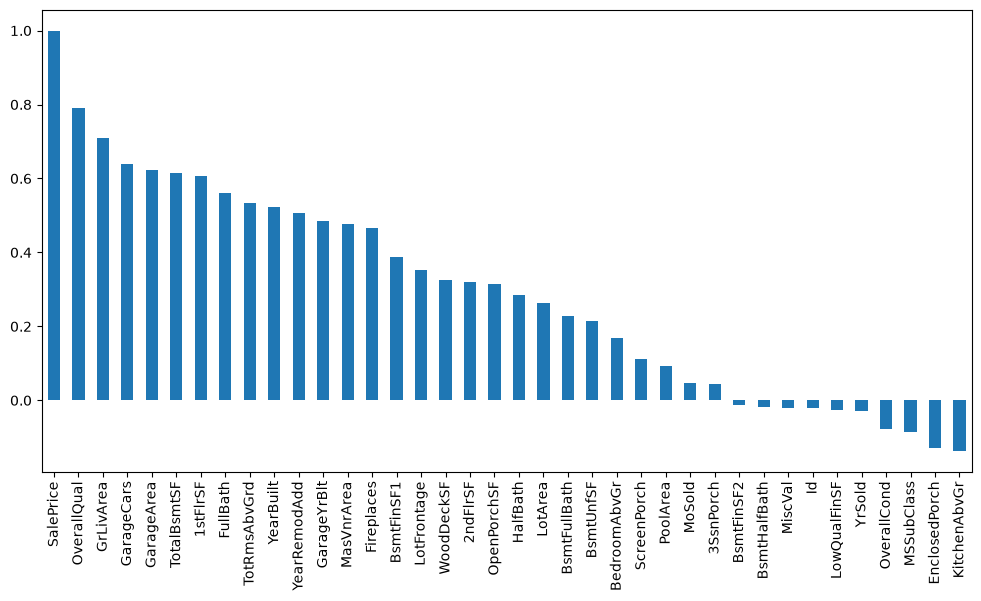

In [12]:
train.corr(numeric_only=True)['SalePrice'].sort_values(ascending=False).plot(kind='bar',figsize=(12,6))

In [13]:
# dropping because it affect very less on saleprice
train = train.drop(columns=['Id','Street','Utilities','Condition2','RoofMatl','Condition1','BsmtFinType2','BsmtFinSF2','Heating','Electrical','LowQualFinSF','BsmtHalfBath','GarageCond','PavedDrive','OpenPorchSF','EnclosedPorch','3SsnPorch','ScreenPorch','PoolArea','MiscVal','MoSold','YrSold'])
test = test.drop(columns=['Id','Street','Utilities','Condition2','RoofMatl','Condition1','BsmtFinType2','BsmtFinSF2','Heating','Electrical','LowQualFinSF','BsmtHalfBath','GarageCond','PavedDrive','OpenPorchSF','EnclosedPorch','3SsnPorch','ScreenPorch','PoolArea','MiscVal','MoSold','YrSold'])

In [14]:
train.shape

(1460, 53)

In [15]:
test.shape

(1459, 52)

In [17]:
from ydata_profiling import ProfileReport
profile = ProfileReport(train, title="Data Report")
profile.to_file("after_column_removed.html")

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|█████████████████████████████████████████████████████████████████████████████████| 53/53 [00:00<00:00, 125.85it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

In [18]:
train[train.isnull().any(axis=1)]

,MSSubClass,MSZoning,LotFrontage,LotArea,LotShape,LandContour,LotConfig,LandSlope,Neighborhood,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,Exterior1st,Exterior2nd,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtUnfSF,TotalBsmtSF,HeatingQC,CentralAir,1stFlrSF,2ndFlrSF,GrLivArea,BsmtFullBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,WoodDeckSF,SaleType,SaleCondition,SalePrice
7,60,RL,NaN,10382,IR1,Lvl,Corner,Gtl,NWAmes,1Fam,2Story,7,6,1973,1973,Gable,HdBoard,HdBoard,240.0,TA,TA,CBlock,Gd,TA,Mn,ALQ,859,216,1107,Ex,Y,1107,983,2090,1,2,1,3,1,TA,7,Typ,2,Attchd,1973.0,RFn,2,484,TA,235,WD,Normal,200000
12,20,RL,NaN,12968,IR2,Lvl,Inside,Gtl,Sawyer,1Fam,1Story,5,6,1962,1962,Hip,HdBoard,Plywood,0.0,TA,TA,CBlock,TA,TA,No,ALQ,737,175,912,TA,Y,912,0,912,1,1,0,2,1,TA,4,Typ,0,Detchd,1962.0,Unf,1,352,TA,140,WD,Normal,144000
14,20,RL,NaN,10920,IR1,Lvl,Corner,Gtl,NAmes,1Fam,1Story,6,5,1960,1960,Hip,MetalSd,MetalSd,212.0,TA,TA,CBlock,TA,TA,No,BLQ,733,520,1253,TA,Y,1253,0,1253,1,1,1,2,1,TA,5,Typ,1,Attchd,1960.0,RFn,1,352,TA,0,WD,Normal,157000
16,20,RL,NaN,11241,IR1,Lvl,CulDSac,Gtl,NAmes,1Fam,1Story,6,7,1970,1970,Gable,Wd Sdng,Wd Sdng,180.0,TA,TA,CBlock,TA,TA,No,ALQ,578,426,1004,Ex,Y,1004,0,1004,1,1,0,2,1,TA,5,Typ,1,Attchd,1970.0,Fin,2,480,TA,0,WD,Normal,149000
17,90,RL,72.0,10791,Reg,Lvl,Inside,Gtl,Sawyer,Duplex,1Story,4,5,1967,1967,Gable,MetalSd,MetalSd,0.0,TA,TA,Slab,NaN,NaN,NaN,NaN,0,0,0,TA,Y,1296,0,1296,0,2,0,2,2,TA,6,Typ,0,CarPort,1967.0,Unf,2,516,TA,0,WD,Normal,90000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1443,30,RL,NaN,8854,Reg,Lvl,Inside,Gtl,BrkSide,1Fam,1.5Unf,6,6,1916,1950,Gable,Wd Sdng,Wd Sdng,0.0,TA,TA,BrkTil,TA,TA,No,Unf,0,952,952,Fa,N,952,0,952,0,1,0,2,1,Fa,4,Typ,1,Detchd,1916.0,Unf,1,192,Fa,0,WD,Normal,121000
1446,20,RL,NaN,26142,IR1,Lvl,CulDSac,Gtl,Mitchel,1Fam,1Story,5,7,1962,1962,Gable,HdBoard,HdBoard,189.0,TA,TA,CBlock,TA,TA,No,Rec,593,595,1188,TA,Y,1188,0,1188,0,1,0,3,1,TA,6,Typ,0,Attchd,1962.0,Unf,1,312,TA,261,WD,Normal,157900
1449,180,RM,21.0,1533,Reg,Lvl,Inside,Gtl,MeadowV,Twnhs,SFoyer,5,7,1970,1970,Gable,CemntBd,CmentBd,0.0,TA,TA,CBlock,Gd,TA,Av,GLQ,553,77,630,Ex,Y,630,0,630,1,1,0,1,1,Ex,3,Typ,0,NaN,NaN,NaN,0,0,NaN,0,WD,Abnorml,92000
1450,90,RL,60.0,9000,Reg,Lvl,FR2,Gtl,NAmes,Duplex,2Story,5,5,1974,1974,Gable,VinylSd,VinylSd,0.0,TA,TA,CBlock,Gd,TA,No,Unf,0,896,896,TA,Y,896,896,1792,0,2,2,4,2,TA,8,Typ,0,NaN,NaN,NaN,0,0,NaN,32,WD,Normal,136000


In [90]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder,OrdinalEncoder,StandardScaler
from sklearn.linear_model import ElasticNet

In [91]:
numeric_feature = ['MSSubClass',
 'LotArea',
 'OverallQual',
 'OverallCond',
 'YearBuilt',
 'YearRemodAdd',
 'BsmtFinSF1',
 'BsmtUnfSF',
 'TotalBsmtSF',
 '1stFlrSF',
 '2ndFlrSF',
 'GrLivArea',
 'BsmtFullBath',
 'FullBath',
 'HalfBath',
 'BedroomAbvGr',
 'KitchenAbvGr',
 'TotRmsAbvGrd',
 'Fireplaces',
 'GarageCars',
 'GarageArea',
 'WoodDeckSF','LotFrontage', 'MasVnrArea', 'GarageYrBlt']

In [92]:
ohe_feat =  ['MSZoning','LandContour','LotConfig','LandSlope','Neighborhood','BldgType','RoofStyle','Exterior1st','Exterior2nd','Foundation','GarageType','SaleType','SaleCondition','HouseStyle']

In [93]:
ordinal_feat = ['LotShape','ExterQual','ExterCond','BsmtQual','BsmtCond','BsmtExposure','BsmtFinType1','HeatingQC','CentralAir','KitchenQual','Functional','GarageFinish','GarageQual']

In [94]:
categories = [
    ['IR3','IR2','IR1','Reg'],
    ['Fa','TA','Gd','Ex'],
    ['Po','Fa','TA','Gd','Ex'],
    ['Fa','TA','Gd','Ex'],
    ['Po','Fa','TA','Gd'],
    ['No','Mn','Av','Gd'],
    ['Unf','LwQ','Rec','BLQ','ALQ','GLQ'], 
    ['Po','Fa','TA','Gd','Ex'], 
    ['N','Y'],
    ['Fa','TA','Gd','Ex'],
    ['Sev', 'Maj2', 'Maj1', 'Mod', 'Min2', 'Min1', 'Typ'], 
    ['Unf','RFn','Fin'], 
    ['Po','Fa','TA','Gd','Ex']
]

In [95]:
train['Fireplaces'].value_counts()

Fireplaces
0    690
1    650
2    115
3      5
Name: count, dtype: int64

In [96]:
ord_pipe = Pipeline([
    ('imputer',SimpleImputer(strategy='most_frequent')),
    ('ord_encoding',OrdinalEncoder(categories=categories,handle_unknown='use_encoded_value',unknown_value=-1)),
    ('scaler',StandardScaler())
])

In [97]:
ohe_pipe = Pipeline([
    ('imputer',SimpleImputer(strategy='most_frequent')),
    ('ohe_encoding',OneHotEncoder(drop='first',dtype=np.int32,sparse_output=False,handle_unknown='ignore'))
])

In [98]:
num_pipe = Pipeline([
    ('imputer',SimpleImputer(strategy='median')),
    ('scaler',StandardScaler())
])

In [99]:
preprocessor = ColumnTransformer([
    ('ordinal',ord_pipe,ordinal_feat),
    ('onehot',ohe_pipe,ohe_feat),
    ('num',num_pipe,numeric_feature)
])

In [100]:
pipe_model = Pipeline([
    ('preprocessor',preprocessor),
    ('model',ElasticNet(l1_ratio=0.01,alpha=0.3,max_iter=10000))
])

In [101]:
from sklearn.model_selection import train_test_split

In [102]:
x = train.iloc[:,0:-1]
y= train.iloc[:,-1]

In [103]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [104]:
pipe_model.fit(x_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('ordinal', ...), ('onehot', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different tra

In [105]:
y_pred = pipe_model.predict(x_test)

In [106]:
from sklearn.metrics import r2_score


In [107]:
from sklearn.model_selection import cross_val_score

In [108]:
r2_score(y_test,y_pred)

0.8441428203526525

In [109]:
np.average(cross_val_score(pipe_model,x_train,y_train,cv=5,scoring='r2'))

C:\Users\bhard\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:261: UserWarning: Found unknown categories in columns [7] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
C:\Users\bhard\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:261: UserWarning: Found unknown categories in columns [6] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
C:\Users\bhard\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:261: UserWarning: Found unknown categories in columns [7, 8] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
C:\Users\bhard\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:261: UserWarning: Found unknown categories in columns [4, 7] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
C:\Users\bhard\anaconda3\L

np.float64(0.8087002166682362)

In [110]:
from sklearn.model_selection import GridSearchCV

In [111]:
params = {
    'model__alpha': [0.001, 0.01, 0.1,0.3,0.4,0.5,0.6, 1, 10],
    'model__l1_ratio': [0.1, 0.3, 0.5, 0.7, 0.9, 1]
}


In [112]:
grid = GridSearchCV(pipe_model,
                   param_grid=params,cv=5 , scoring='r2',n_jobs=-1
                   )

In [113]:
grid.fit(x_train,y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...iter=10000))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__alpha': [0.001, 0.01, ...], 'model__l1_ratio': [0.1, 0.3, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is also di

In [114]:
print(grid.best_params_)
print(grid.best_score_)

{'model__alpha': 0.01, 'model__l1_ratio': 0.3}
0.8192648428995574


In [116]:
#predicting the test file 
pipe_model.predict(test)

array([110765.96560725, 166335.24266989, 178393.85192639, ...,
       164965.94704423, 113810.60792131, 233258.62454927], shape=(1459,))

In [117]:
best_model = grid.best_estimator_

best_pred = best_model.predict(x_test)

print("R2 Score:", r2_score(y_test, best_pred))

R2 Score: 0.8645921917346947


In [118]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
import numpy as np

print("MAE:", mean_absolute_error(y_test, best_pred))

rmse = np.sqrt(mean_squared_error(y_test, best_pred))
print("RMSE:", rmse)

MAE: 19222.3068177005
RMSE: 32227.65986532594


In [119]:
import joblib
joblib.dump(pipe_model,"house_price_pred.pkl")

['house_price_pred.pkl']